# 04 · What forecast errors cost: pricing 10-year term life insurance

Notebooks 02 and 03 measured forecast errors in log death rates. A pricing team cares about something simpler: **did we charge enough?**

Here I price a **10-year level term policy issued in 2015**. Its whole term, 2015–2024, has already happened, so I can compare the premium each mortality assumption *would have charged* with the premium that turned out to be correct.

**Assumptions** (code in `src/pricing.py`)

| Item | Value |
|---|---|
| Product | 10-year level term, $500,000 death benefit, annual premiums paid in advance |
| Issue | 1 Jan 2015, ages 30, 40, 50 and 60, male and female |
| Interest rate | 3% a year |
| Premium | **Net premium only**: expected claims, no expenses, commission, lapses or profit |
| Mortality | Canadian **population** rates (StatCan), each policyholder following their own age/year path |

⚠️ The dollar amounts are **not market prices**. Insured lives are healthier than the population, especially in the first years after medical underwriting, and real premiums include expenses and lapse assumptions. The useful output is the **percentage gap** between assumptions, not the dollar level.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_qx, qx_matrix, qx_to_mx
from src.lee_carter import LeeCarter, random_walk_forecast
from src.ml import ImprovementGBM, blend
from src.pricing import cohort_qx, net_level_premium, pricing_shortfall

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#999999", "axes.labelcolor": "#333333",
    "xtick.color": "#666666", "ytick.color": "#666666", "lines.linewidth": 2,
})
MODEL_COLORS = {"Static 2014 table": "#6b7280", "Lee-Carter": "#257de0", "Naive trend": "#00a080",
                "GBM": "#f47230", "GBM + naive": "#8b5cf6"}
FIG_DIR = "../reports/figures"
SEXES = ["male", "female"]
FACE, RATE, TERM = 500_000, 0.03, 10
ISSUE_YEAR, ISSUE_AGES = 2015, [30, 40, 50, 60]

df = load_qx()
q_all = {s: qx_matrix(df, s) for s in SEXES}
m = {s: qx_to_mx(q_all[s].loc[0:100]) for s in SEXES}
log_m = {s: np.log(m[s]) for s in SEXES}

## 1. The mortality assumptions

The four forecasts from notebooks 02–03, all built with data up to 2014, plus one more:

* **Static 2014 table:** use the latest observed rates and assume **no future improvement**. It is the simplest assumption and, during a long period of improvement, the most conservative one.

In [2]:
def build_forecasts(last_year: int, horizon: int = TERM) -> dict:
    hist = {s: m[s].loc[:, :last_year] for s in SEXES}
    gbm = ImprovementGBM().fit({s: log_m[s].loc[:, :last_year] for s in SEXES}, last_year=last_year)
    future = range(last_year + 1, last_year + horizon + 1)
    fc = {
        "Static 2014 table": {s: pd.DataFrame({y: hist[s][last_year] for y in future}) for s in SEXES},
        "Lee-Carter": {s: LeeCarter().fit(hist[s]).forecast_mx(horizon) for s in SEXES},
        "Naive trend": {s: random_walk_forecast(hist[s], horizon) for s in SEXES},
        "GBM": {s: gbm.forecast_mx(s, horizon) for s in SEXES},
    }
    fc["GBM + naive"] = {s: blend(fc["GBM"][s], fc["Naive trend"][s]) for s in SEXES}
    return fc

fc = build_forecasts(2014)
actual = {s: m[s].loc[:, 2015:2024] for s in SEXES}

## 2. Premiums: what each assumption would have charged

In [3]:
rows = []
for s in SEXES:
    for age in ISSUE_AGES:
        q_true = cohort_qx(actual[s], age, ISSUE_YEAR, TERM)
        p_true = net_level_premium(q_true, FACE, RATE)
        row = {"sex": s, "issue age": age, "Correct (hindsight)": p_true}
        for name, f in fc.items():
            row[name] = net_level_premium(cohort_qx(f[s], age, ISSUE_YEAR, TERM), FACE, RATE)
        rows.append(row)
prem = pd.DataFrame(rows).set_index(["sex", "issue age"])
print("Annual net premium, $500,000 10-year term issued 2015:")
prem.round(0)

Annual net premium, $500,000 10-year term issued 2015:


Correct (hindsight)  Static 2014 table  ...     GBM  GBM + naive
sex    issue age                                          ...                     
male   30                       651.0              467.0  ...   407.0        418.0
       40                      1026.0              902.0  ...   800.0        799.0
       50                      2207.0             2165.0  ...  1908.0       1895.0
       60                      5245.0             5425.0  ...  4751.0       4742.0
female 30                       319.0              259.0  ...   233.0        236.0
       40                       592.0              584.0  ...   533.0        532.0
       50                      1358.0             1390.0  ...  1267.0       1263.0
       60                      3352.0             3454.0  ...  3129.0       3132.0

[8 rows x 6 columns]

In [4]:
gap = prem[list(fc)].div(prem["Correct (hindsight)"], axis=0).sub(1).mul(100)
print("Premium vs. the hindsight-correct premium (%). Negative = under-priced:")
gap.round(1)

Premium vs. the hindsight-correct premium (%). Negative = under-priced:


Static 2014 table  Lee-Carter  Naive trend   GBM  GBM + naive
sex    issue age                                                               
male   30                     -28.3       -38.8        -34.0 -37.5        -35.8
       40                     -12.1       -23.4        -22.2 -22.1        -22.1
       50                      -1.9       -17.0        -14.7 -13.6        -14.1
       60                       3.4       -11.2         -9.8  -9.4         -9.6
female 30                     -18.7       -29.0        -24.8 -26.8        -25.9
       40                      -1.3        -6.1        -10.3  -9.9        -10.1
       50                       2.3        -2.6         -7.4  -6.7         -7.0
       60                       3.1        -1.8         -6.5  -6.6         -6.6

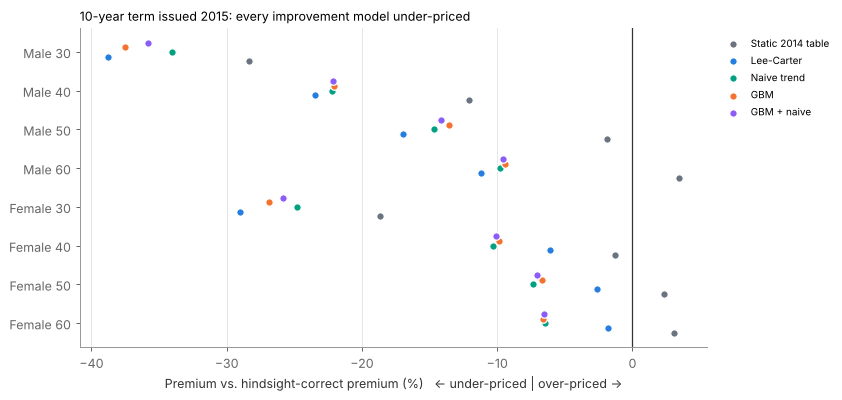

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
labels = [f"{s.capitalize()} {a}" for s, a in gap.index]
y = np.arange(len(labels))[::-1]
ax.axvline(0, color="#333333", lw=1)
for i, name in enumerate(fc):
    ax.scatter(gap[name].values, y + (i - 2) * 0.12, s=36, color=MODEL_COLORS[name], label=name,
               edgecolor="white", linewidth=1, zorder=3)
ax.set_yticks(y, labels)
ax.set_xlabel("Premium vs. hindsight-correct premium (%)   ← under-priced | over-priced →")
ax.set_title("10-year term issued 2015: every improvement model under-priced", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="y", visible=False)
fig.savefig(f"{FIG_DIR}/term_premium_gap.png", bbox_inches="tight", dpi=150)

**What this shows**
* **Every model that assumed improvement under-priced, in all 8 cells.** The gap is largest at young issue ages: for a 30-year-old man, the four forecasting models charged 34–39% less than turned out to be needed.
* The **static 2014 table** (no improvement) was the closest in 7 of the 8 cells, and slightly *over*-priced at ages 50–60. During 2015–2024, assuming no improvement was the safer choice.
* The three forecasting models (Lee-Carter, naive, GBM) priced within a few points of each other at most ages. For term pricing, **whether you assume improvement at all mattered more than which model you used.**
* Even the static table under-priced 30-year-olds by 19–28%, because young-adult mortality actually *rose* over the period.

## 3. In dollars: the shortfall on a block of 10,000 policies

If an insurer sold 10,000 of these policies at each assumption's price and deaths followed what actually happened, how much short would it be? The table shows the present value (at 3%, as of issue) of claims minus premiums, in $ millions. **Positive = the insurer lost money.**

In [6]:
rows = []
for s in SEXES:
    for age in ISSUE_AGES:
        q_true = cohort_qx(actual[s], age, ISSUE_YEAR, TERM)
        rows.append({"sex": s, "issue age": age,
                     **{name: pricing_shortfall(prem.loc[(s, age), name], q_true, FACE, RATE) * 10_000 / 1e6
                        for name in fc}})
shortfall = pd.DataFrame(rows).set_index(["sex", "issue age"])
shortfall.round(1)

Static 2014 table  Lee-Carter  Naive trend   GBM  GBM + naive
sex    issue age                                                               
male   30                      16.1        22.1         19.4  21.4         20.4
       40                      10.8        21.0         19.8  19.8         19.8
       50                       3.6        32.4         28.0  25.9         26.9
       60                     -15.2        49.6         43.3  41.8         42.5
female 30                       5.2         8.1          6.9   7.5          7.2
       40                       0.7         3.2          5.3   5.1          5.2
       50                      -2.8         3.1          8.7   7.9          8.3
       60                      -8.8         5.3         18.6  19.1         18.9

* For 40-year-old men, each improvement model leaves a hole of about **$20 million per 10,000 policies** (about $2,000 per policy). At issue age 60 it is $42–50 million.
* The static table also lost money at younger issue ages (men 30–50, women 30–40), but less. It made a margin at age 60 for both sexes and for women at 50.
* Real-world losses would be smaller, because insurers add margins, use select (underwritten) mortality, and have some policies lapse. Even so, the *direction* of the error is the risk to watch.

## 4. Is this just COVID? A 5-year term issued in 2015 (2015–2019)

The 2015–2024 window includes the pandemic. To check whether the under-pricing is only a COVID effect, I repeat the test for a **5-year term** that ended before 2020.

In [7]:
rows = []
for s in SEXES:
    for age in ISSUE_AGES:
        p_true = net_level_premium(cohort_qx(actual[s], age, ISSUE_YEAR, 5), FACE, RATE)
        rows.append({"sex": s, "issue age": age,
                     **{name: (net_level_premium(cohort_qx(f[s], age, ISSUE_YEAR, 5), FACE, RATE) / p_true - 1) * 100
                        for name, f in fc.items()}})
gap5 = pd.DataFrame(rows).set_index(["sex", "issue age"])
print("5-year term, premium vs. hindsight-correct (%):")
gap5.round(1)

5-year term, premium vs. hindsight-correct (%):


Static 2014 table  Lee-Carter  Naive trend   GBM  GBM + naive
sex    issue age                                                               
male   30                     -16.0       -28.6        -19.2 -23.7        -21.5
       40                      -5.9       -12.2        -11.3 -11.6        -11.4
       50                       1.4        -8.2         -5.6  -4.8         -5.2
       60                       3.8        -5.2         -3.7  -3.5         -3.6
female 30                      -5.6       -19.0         -8.6 -13.4        -11.0
       40                       0.8        -0.7         -4.1  -3.7         -3.9
       50                       2.7         2.4         -2.4  -1.9         -2.2
       60                       2.7         2.2         -2.6  -2.7         -2.6

* **Under-pricing at young ages started before the pandemic.** For men aged 30, all assumptions were 16–29% too low over 2015–2019, and for men aged 40, 6–12% too low. This is the young-adult mortality reversal from notebook 01.
* At ages 50–60, pre-pandemic errors are smaller: within about ±8% for men and ±3% for women. So most of the older-age gap in section 2 comes from the COVID years.

## 5. For scale: how much does the interest rate matter?

Pricing teams spend a lot of time on interest assumptions. For a 10-year term, how does a 1-point change compare with the choice of mortality model?

In [8]:
rows = []
for s in SEXES:
    q_true = cohort_qx(actual[s], 40, ISSUE_YEAR, TERM)
    base = net_level_premium(q_true, FACE, RATE)
    model_spread = gap.loc[(s, 40)].max() - gap.loc[(s, 40)].min()
    rows.append({"sex": s,
                 "interest 2% vs 3%": (net_level_premium(q_true, FACE, 0.02) / base - 1) * 100,
                 "interest 4% vs 3%": (net_level_premium(q_true, FACE, 0.04) / base - 1) * 100,
                 "spread across mortality assumptions (pts)": model_spread})
pd.DataFrame(rows).set_index("sex").round(1)

,interest 2% vs 3%,interest 4% vs 3%,spread across mortality assumptions (pts)
sex,,,
male,1.8,-1.7,11.3
female,1.8,-1.7,9.0


For a 10-year term at age 40, moving the interest rate by 1 point changes the premium by under **2%**. The choice of mortality assumption moved it by **9–11 points**. For short-term protection products, the mortality assumption is the main pricing risk.

## 6. Pricing today: a 10-year term issued in 2025

Finally, the forward-looking question: refit every model on all data through 2024 and price a policy issued in 2025. There is no "correct" answer yet. The point is to see **how far apart reasonable assumptions are today**. (The static table here uses 2024 rates.)

In [9]:
fc_now = build_forecasts(2024)
rows = []
for s in SEXES:
    for age in ISSUE_AGES:
        rows.append({"sex": s, "issue age": age,
                     **{name.replace("2014", "2024"): net_level_premium(cohort_qx(f[s], age, 2025, TERM), FACE, RATE)
                        for name, f in fc_now.items()}})
prem_now = pd.DataFrame(rows).set_index(["sex", "issue age"])
prem_now["spread %"] = (prem_now.max(axis=1) / prem_now.min(axis=1) - 1) * 100
prem_now.round(0)

Static 2024 table  Lee-Carter  ...  GBM + naive  spread %
sex    issue age                                 ...                       
male   30                     658.0       498.0  ...        623.0      32.0
       40                    1072.0       882.0  ...       1034.0      22.0
       50                    2183.0      1942.0  ...       2029.0      12.0
       60                    5065.0      4752.0  ...       4633.0      12.0
female 30                     339.0       261.0  ...        351.0      44.0
       40                     609.0       559.0  ...        588.0       9.0
       50                    1316.0      1288.0  ...       1225.0       9.0
       60                    3204.0      3187.0  ...       2963.0       9.0

[8 rows x 6 columns]

* The assumptions now disagree a lot: up to **22% at age 40 for men** and **32–44% at age 30**.
* They also changed order. Refitted on data that includes the recent worsening, **GBM now prices at or above the static table** for 40-year-old men and 30-year-old women, i.e. it projects further deterioration there. It has picked up the post-2010 trend from its "recent improvement" inputs (which now include the pandemic years, so some of this may not last). Lee-Carter, which averages the trend over 1980–2024, is still the cheapest in 5 of the 8 cells.
* Which is right depends on whether the young-adult deterioration and the pandemic years carry on or fade, and that is a judgement the data alone can't settle. In practice, this is where a pricing actuary would add scenario testing and margins rather than pick one model's central estimate.

## 7. Conclusions

1. **Assuming mortality improvement was the expensive mistake.** For 10-year term issued in 2015, every improvement-based model under-priced at every issue age, by 34–39% for 30-year-old men and about 22% for 40-year-old men. The no-improvement table came closest in 7 of 8 cases.
2. **The choice between forecasting models mattered much less** than whether to assume improvement at all. Lee-Carter, the naive trend and gradient boosting were usually within a few points of each other.
3. **Young-adult under-pricing began before COVID.** The pandemic made older-age errors bigger, but the young-adult problem showed up in 2015–2019.
4. **Today, reasonable assumptions differ by 9–44% in net premium**, more than five times the effect of moving the interest rate by 1 point. Under model-risk rules like OSFI E-23, that range is the thing to disclose and stress-test, not hide behind one central estimate.

**Limits:** population (not insured) mortality, net premiums only, one issue year, and a single 10-year window that contains both an overdose crisis and a pandemic. With longer data and insured-lives experience, the size of these gaps would change; the direction would need re-testing.